In [ ]:
# Environnement : en local, lancer le notebook depuis la racine du depot.
# Sur Google Colab, on clone le depot puis on se place dedans.
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('models'):
    os.system('git clone https://github.com/AISSAOUI-15/generative-image-reconstruction.git')
    os.chdir('generative-image-reconstruction')

In [ ]:
from __future__ import print_function
import matplotlib.pyplot as plt
%matplotlib inline

import os
# os.environ['CUDA_VISIBLE_DEVICES'] = '1'

import numpy as np
from models.resnet import ResNet
from models.unet import UNet
from models.skip import skip
import torch
import torch.optim

from utils.inpainting_utils import *

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark =True
dtype = torch.cuda.FloatTensor

PLOT = True
imsize = -1
dim_div_by = 64

In [ ]:
## Fig 6
# img_path  = 'data/inpainting/vase.png'
# mask_path = 'data/inpainting/vase_mask.png'

## Fig 8
img_path  = 'data/inpainting/AISSAOUI Mohamed.jpg'
mask_path = 'data/inpainting/kate_mask1.png'

## Fig 7 (top)
# img_path  = 'data/inpainting/kate.png'
# mask_path = 'data/inpainting/kate_mask.png'

# Another text inpainting example
# img_path  = 'data/inpainting/peppers.png'
# mask_path = 'data/inpainting/peppers_mask.png'

NET_TYPE = 'ResNet' # one of skip_depth4|skip_depth2|UNET|ResNet

In [ ]:
img_pil, img_np = get_image(img_path, imsize)
img_mask_pil, img_mask_np = get_image(mask_path, imsize)

In [ ]:
img_mask_pil = crop_image(img_mask_pil, dim_div_by)
img_pil      = crop_image(img_pil,      dim_div_by)

img_np      = pil_to_np(img_pil)
img_mask_np = pil_to_np(img_mask_pil)

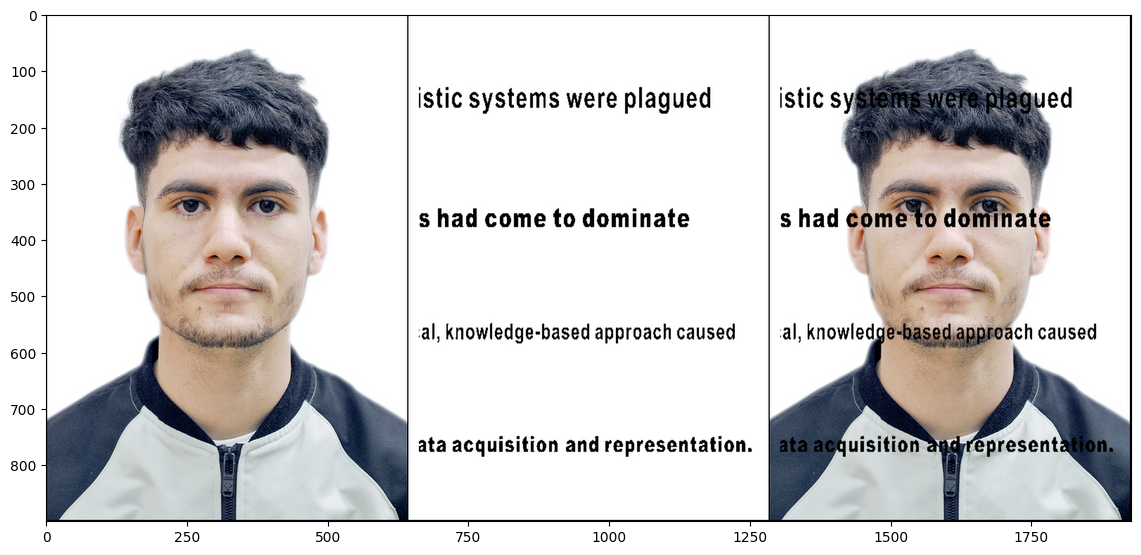

In [ ]:
img_mask_var = np_to_torch(img_mask_np).type(dtype)

plot_image_grid([img_np, img_mask_np, img_mask_np*img_np], 3,11);

In [ ]:
pad = 'reflection' # 'zero'
OPT_OVER = 'net'
OPTIMIZER = 'adam'

In [ ]:

INPUT = 'noise'
input_depth = 1

num_iter = 3000
show_every = 500
figsize = 8
reg_noise_std = 0.00
param_noise = True

if 'skip' in NET_TYPE:

    depth = int(NET_TYPE[-1])
    net = skip(input_depth, img_np.shape[0],
               num_channels_down = [16, 32, 64, 128, 128, 128][:depth],
               num_channels_up =   [16, 32, 64, 128, 128, 128][:depth],
               num_channels_skip =    [0, 0, 0, 0, 0, 0][:depth],
               filter_size_up = 3,filter_size_down = 5,  filter_skip_size=1,
               upsample_mode='nearest', # downsample_mode='avg',
               need1x1_up=False,
               need_sigmoid=True, need_bias=True, pad=pad, act_fun='LeakyReLU').type(dtype)

    LR = 0.01

elif NET_TYPE == 'UNET':

    net = UNet(num_input_channels=input_depth, num_output_channels=3,
                   feature_scale=8, more_layers=1,
                   concat_x=False, upsample_mode='deconv',
                   pad='zero', norm_layer=torch.nn.InstanceNorm2d, need_sigmoid=True, need_bias=True)

    LR = 0.001
    param_noise = False

elif NET_TYPE == 'ResNet':

    net = ResNet(input_depth, img_np.shape[0], 8, 32, need_sigmoid=True, act_fun='LeakyReLU')

    LR = 0.001
    param_noise = False

else:
    assert False

net = net.type(dtype)
net_input = get_noise(input_depth, INPUT, img_np.shape[1:]).type(dtype)

In [ ]:
# Compute number of parameters
s  = sum(np.prod(list(p.size())) for p in net.parameters())
print ('Number of params: %d' % s)

# Loss
mse = torch.nn.MSELoss().type(dtype)

img_var = np_to_torch(img_np).type(dtype)
mask_var = np_to_torch(img_mask_np).type(dtype)

Number of params: 158979


Starting optimization with ADAM


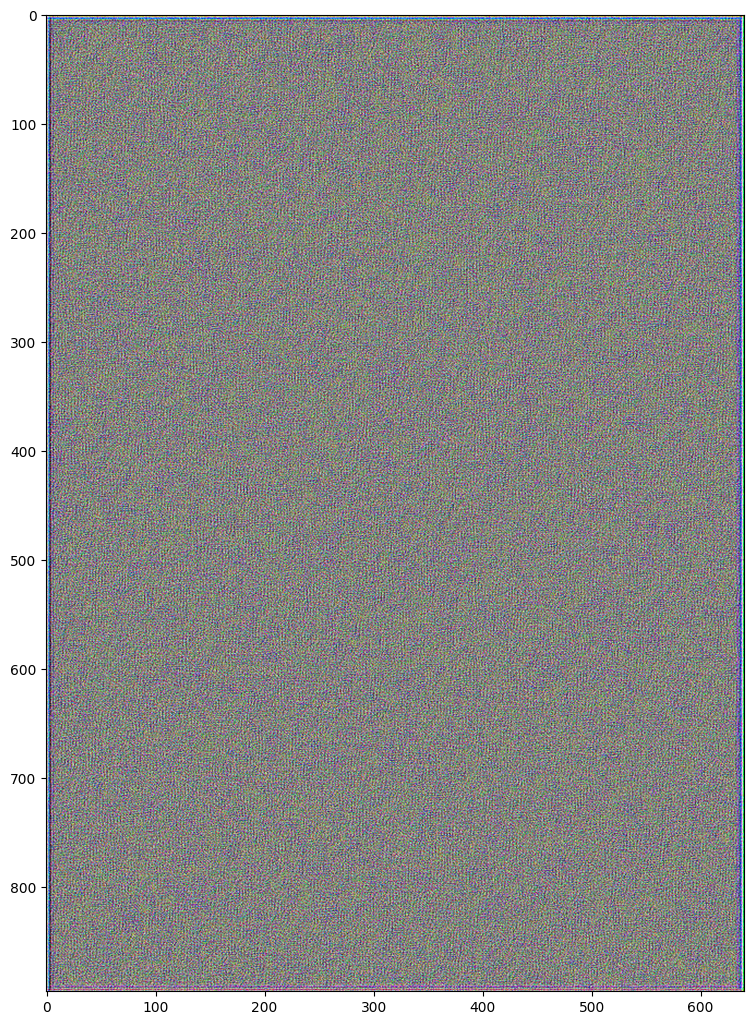

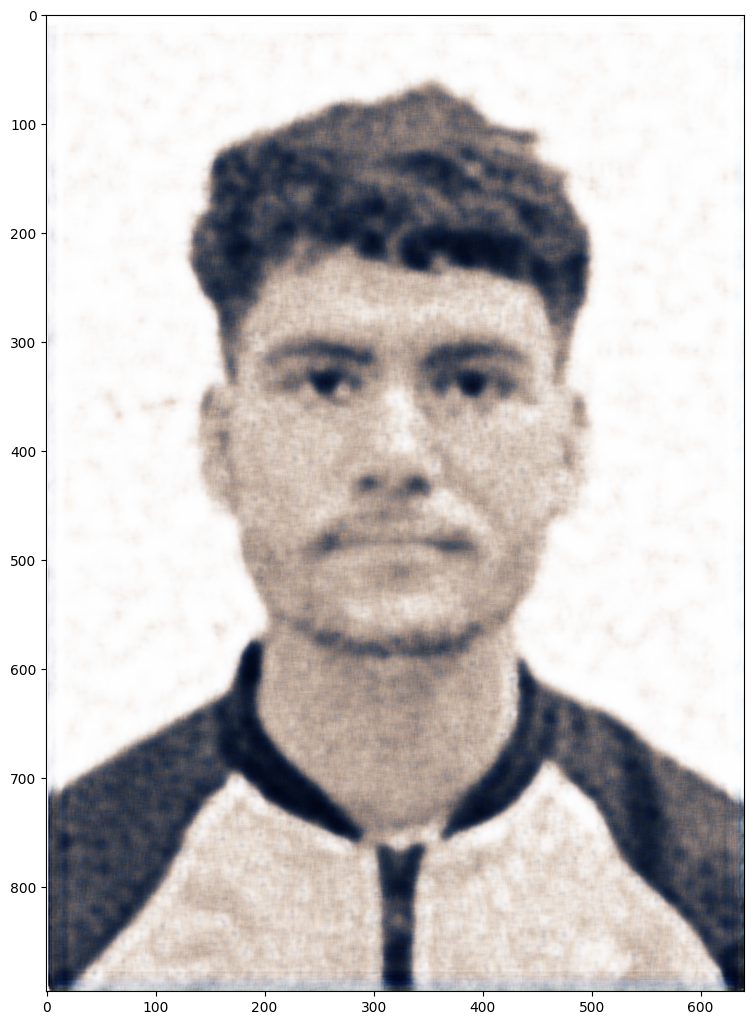

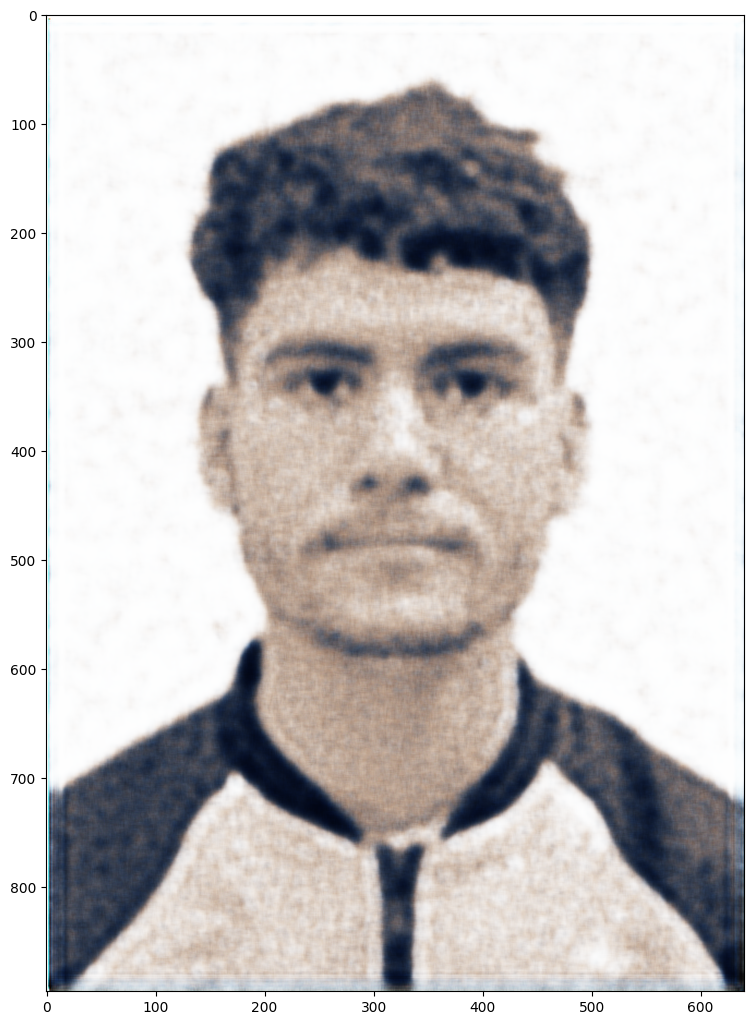

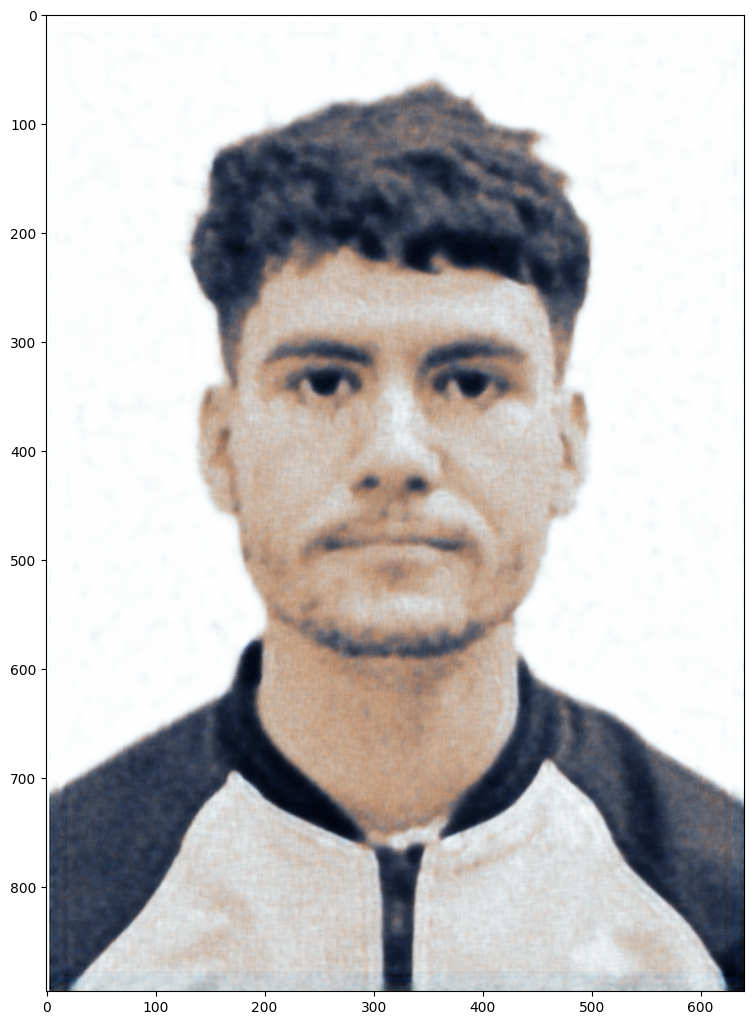

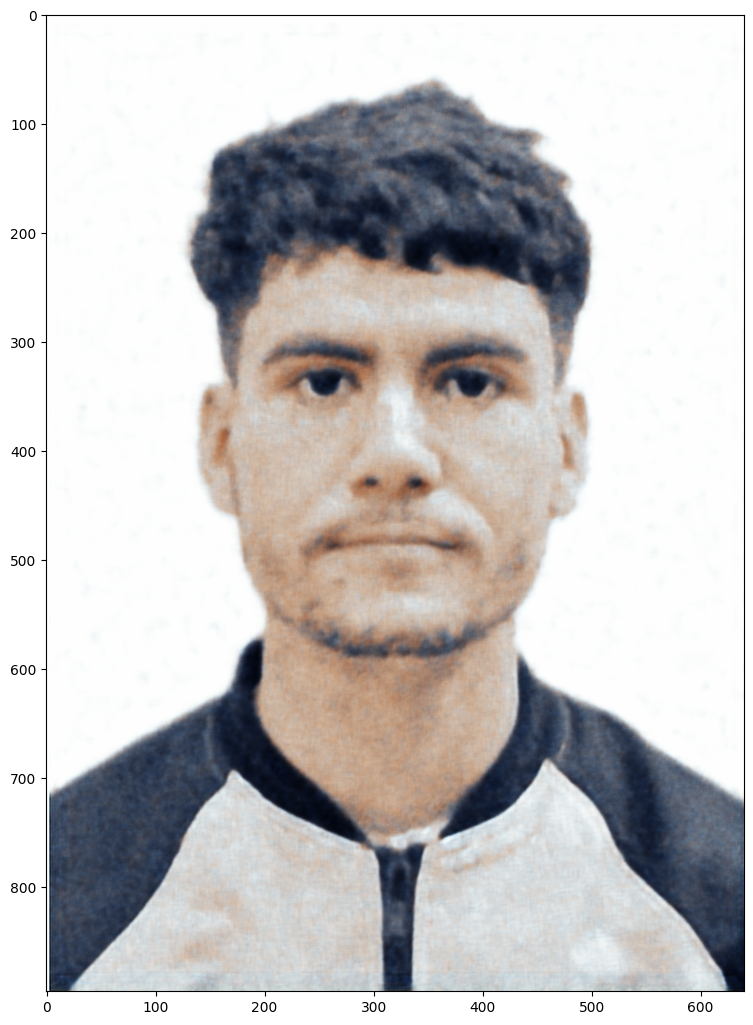

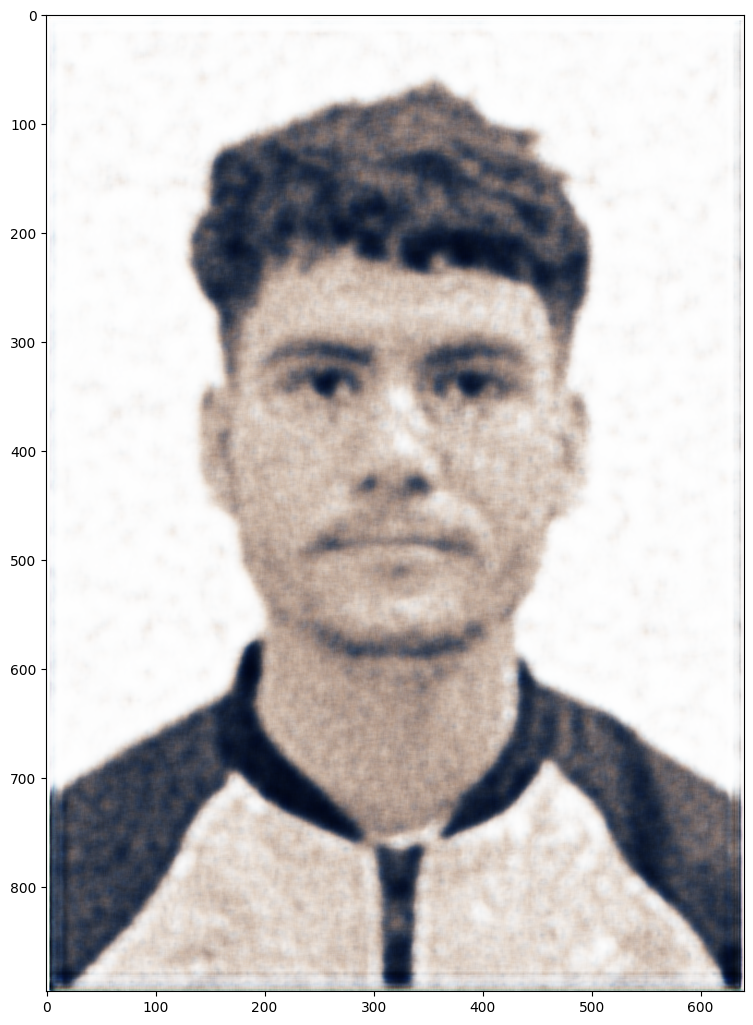

In [ ]:
from skimage.metrics import mean_squared_error
i = 0
Iter_loss = []
def closure():

    global i

    if param_noise:
        for n in [x for x in net.parameters() if len(x.size()) == 4]:
            n = n + n.detach().clone().normal_() * n.std() / 50

    net_input = net_input_saved
    if reg_noise_std > 0:
        net_input = net_input_saved + (noise.normal_() * reg_noise_std)


    out = net(net_input)

    total_loss = mse(out * mask_var, img_var * mask_var)
    Iter_mse = mean_squared_error(out.detach().cpu().numpy()[0], img_np)
    Iter_loss.append(Iter_mse)
    total_loss.backward()

    print ('Iteration %05d    Loss %f' % (i, total_loss.item()), '\r', end='')
    if  PLOT and i % show_every == 0:
        out_np = torch_to_np(out)
        plot_image_grid([np.clip(out_np, 0, 1)], factor=figsize, nrow=1)

    i += 1

    return total_loss

net_input_saved = net_input.detach().clone()
noise = net_input.detach().clone()

p = get_params(OPT_OVER, net, net_input)
optimize(OPTIMIZER, p, closure, LR, num_iter)

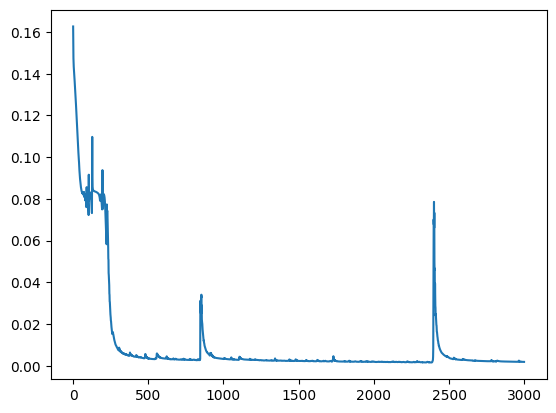

In [ ]:
plt.plot(Iter_loss)

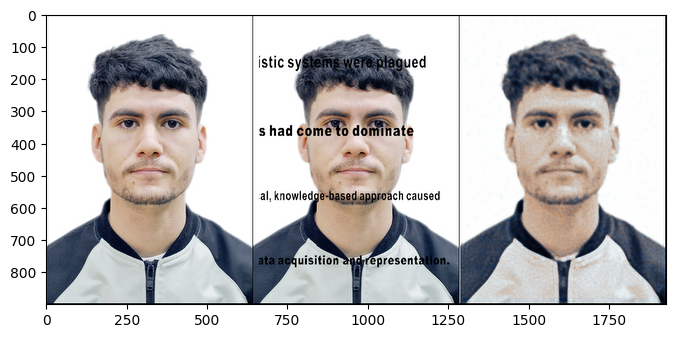

In [ ]:
out_np = torch_to_np(net(net_input))
plot_image_grid([img_np, img_mask_np*img_np,out_np], factor=5);

In [ ]:

from skimage.metrics import peak_signal_noise_ratio

In [ ]:
psrn_gt_sm = peak_signal_noise_ratio(img_np, out_np)
print("PSNR :",psrn_gt_sm)


import torch.nn.functional as F
# Convertir les tableaux NumPy en tenseurs PyTorch
img_noisy_tensor = torch.from_numpy( img_mask_np*img_np).type(dtype)
out_tensor = torch.from_numpy(out_np).type(dtype)

# Calculer le MSE
mse = F.mse_loss(out_tensor, img_noisy_tensor)

# La variable 'mse' contient maintenant la valeur du MSE
print(f"Mean Squared Error (MSE) entre img_noisy_np et out_np : {mse.item()}")

from skimage.metrics import structural_similarity as ssim
# Initialiser une liste pour stocker les valeurs SSIM pour chaque canal
ssim_values = []

# Calculer SSIM pour chaque canal
for i in range(img_np.shape[0]):
    ssim_channel = ssim(img_np[i], out_np[i], data_range=out_np.max() - out_np.min())
    ssim_values.append(ssim_channel)

# Calculer la moyenne des valeurs SSIM pour chaque canal
ssim_mean = np.mean(ssim_values)

print("SSIM moyen  :", ssim_mean)

PSNR : 27.198475790885457
Mean Squared Error (MSE) entre img_noisy_np et out_np : 0.022923484444618225
SSIM moyen  : 0.787073555859152


In [ ]:
img_np = img_np.squeeze()
out_np = out_np.squeeze()
mse = np.mean((img_np - out_np) ** 2)
mse

0.0019061292